# GLM-HMM states, session by session (BWM)

Does the GLM-HMM posterior follow what the mouse is actually doing? Per session, two rows:
1. **Posterior**: P(engaged) (solid) and P(disengaged) (dashed). Grey shading = trials whose most likely state is disengaged.
2. **Behaviour**: block as background colour; choices (top = right, bottom = left; filled = correct, open = error; size = |contrast|); rolling accuracy over all trials and over easy trials (|contrast| ≥ 25%).

States are from `merged_behavioral_and_states.pqt` (engaged.py's per-mouse K=2 fits). Choice is rebuilt from stimulus side and reward (exact, except no-go trials, ~0.4%). Which state is engaged is checked per mouse (higher easy-trial accuracy). Functions: `session_states_plots.py`.

One PNG per session is saved to `results/glmhmm_sessions/<animal>/`.

In [1]:
import sys, pathlib
_p = pathlib.Path.cwd().resolve()
while not (_p / 'paper_style.py').exists() and _p != _p.parent:
    _p = _p.parent
sys.path.insert(0, str(_p)); sys.path.insert(0, str(_p / 'GLM-HMM'))
import paper_style as ps
ps.use('paper')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import session_states_plots as sp

# ---- parameters ----
N_SESSIONS = 20      # sessions to plot and save
PER_ANIMAL = None    # at most this many per animal (None = no limit)
ANIMALS = None       # list of animals, or None for all
SEED = 0             # which random sessions
SHOW = 3             # how many to also show here
OUT_DIR = _p / 'results' / 'glmhmm_sessions'

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


In [2]:
d = sp.load_states()
eng = pd.Series(d.attrs['engaged_state']).value_counts()
print(f"{d['animal'].nunique()} animals, {d['eid'].nunique()} sessions, {len(d)} trials")
print('engaged state per animal:', eng.to_dict())
check = d[d['easy']].groupby(['animal', 'map_state'])['correct'].mean().unstack()
print(f"easy accuracy, engaged > disengaged in {(check['engaged'] > check['disengaged']).sum()} / {check.dropna().shape[0]} animals")
check.describe().round(2)

139 animals, 459 sessions, 296090 trials
engaged state per animal: {'p_state1': 136, 'p_state2': 3}
easy accuracy, engaged > disengaged in 139 / 139 animals


map_state,disengaged,engaged
count,139.00,139.00
mean,0.56,0.97
std,0.27,0.03
min,0.00,0.83
25%,0.38,0.96
50%,0.62,0.98
75%,0.78,0.99
max,0.98,1.00


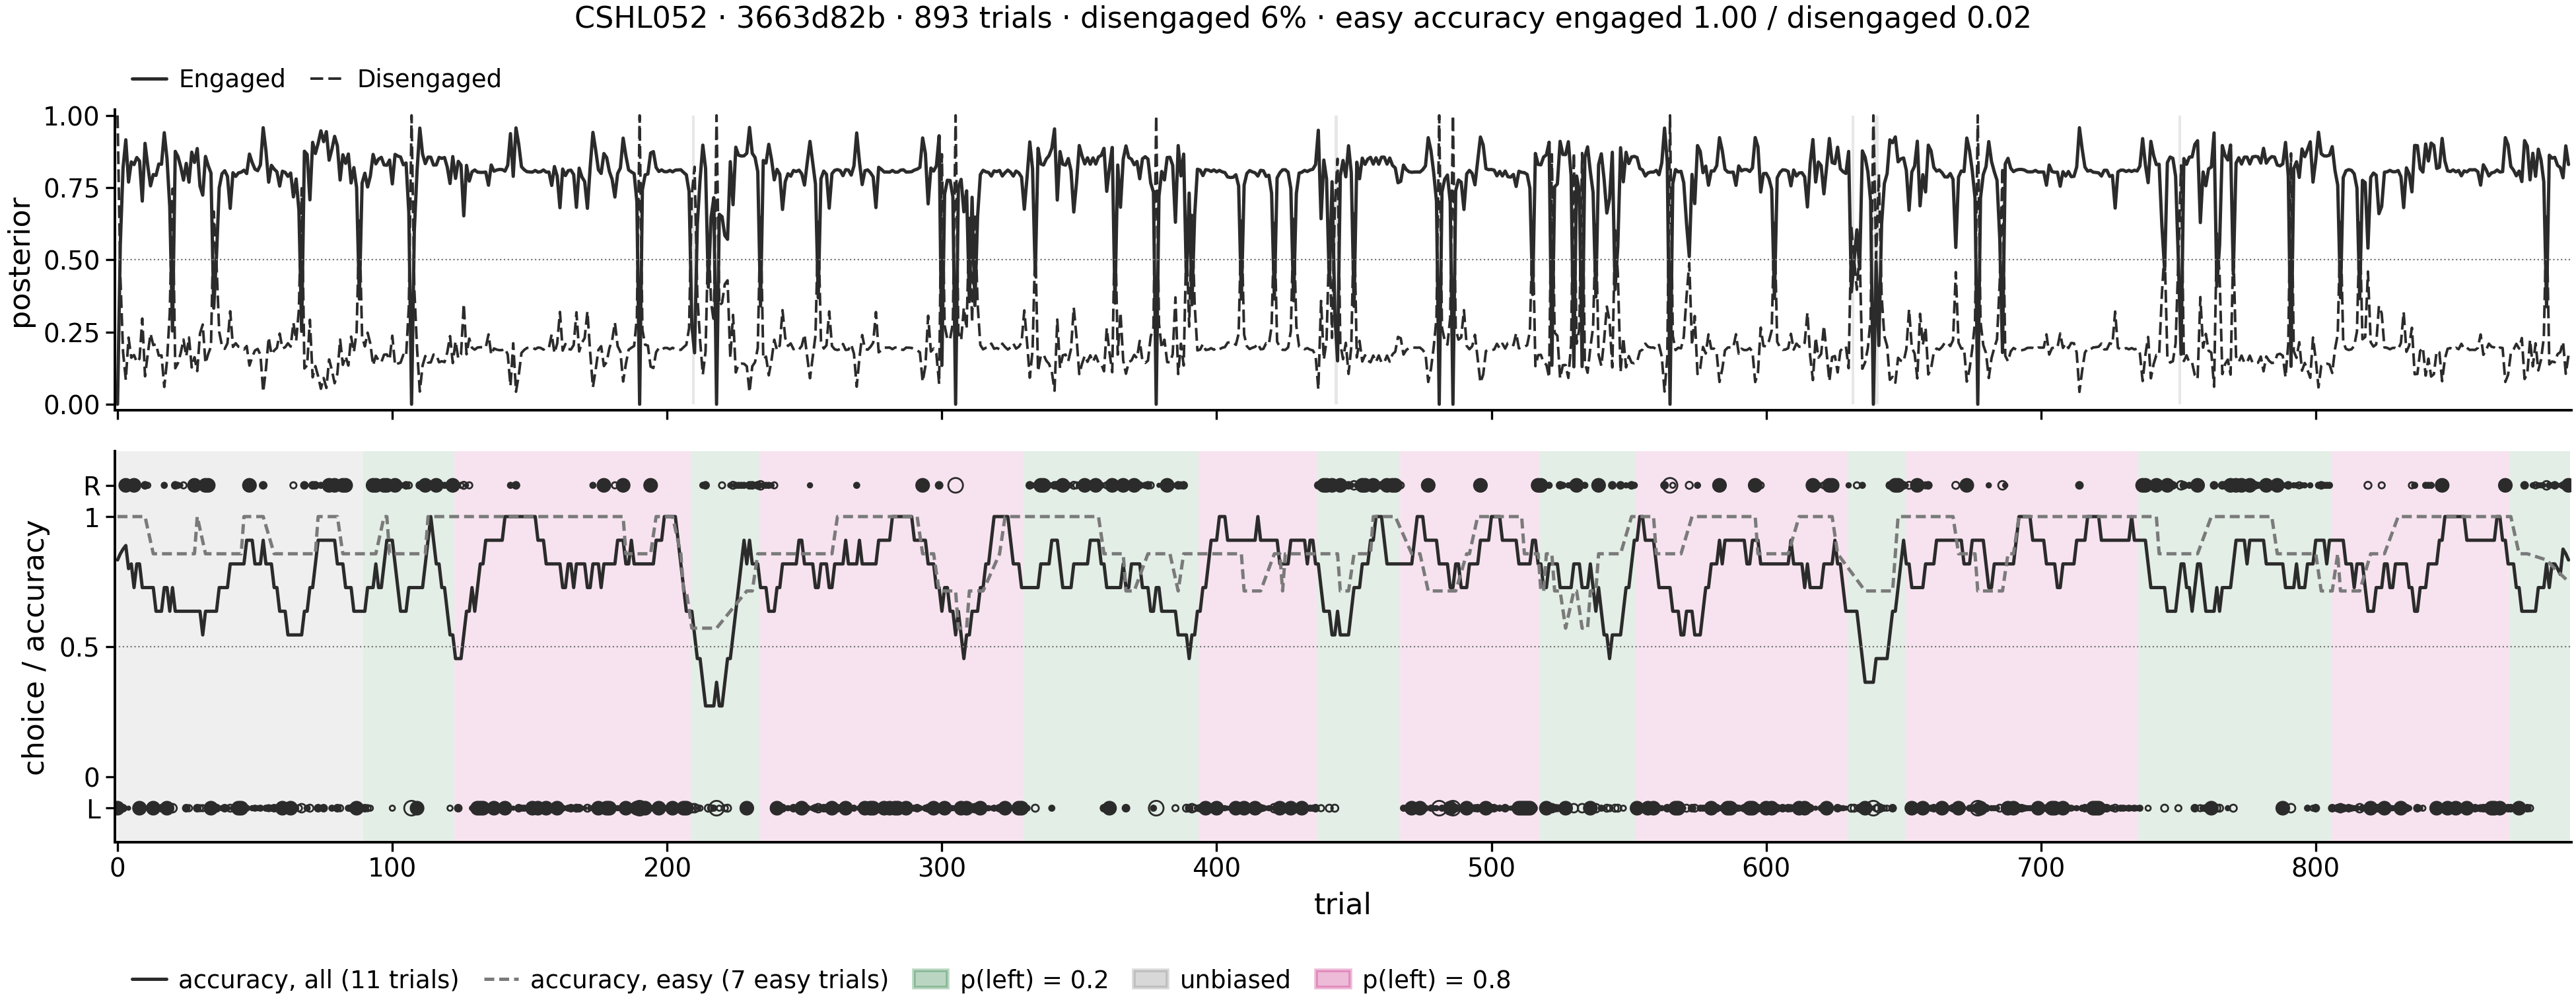

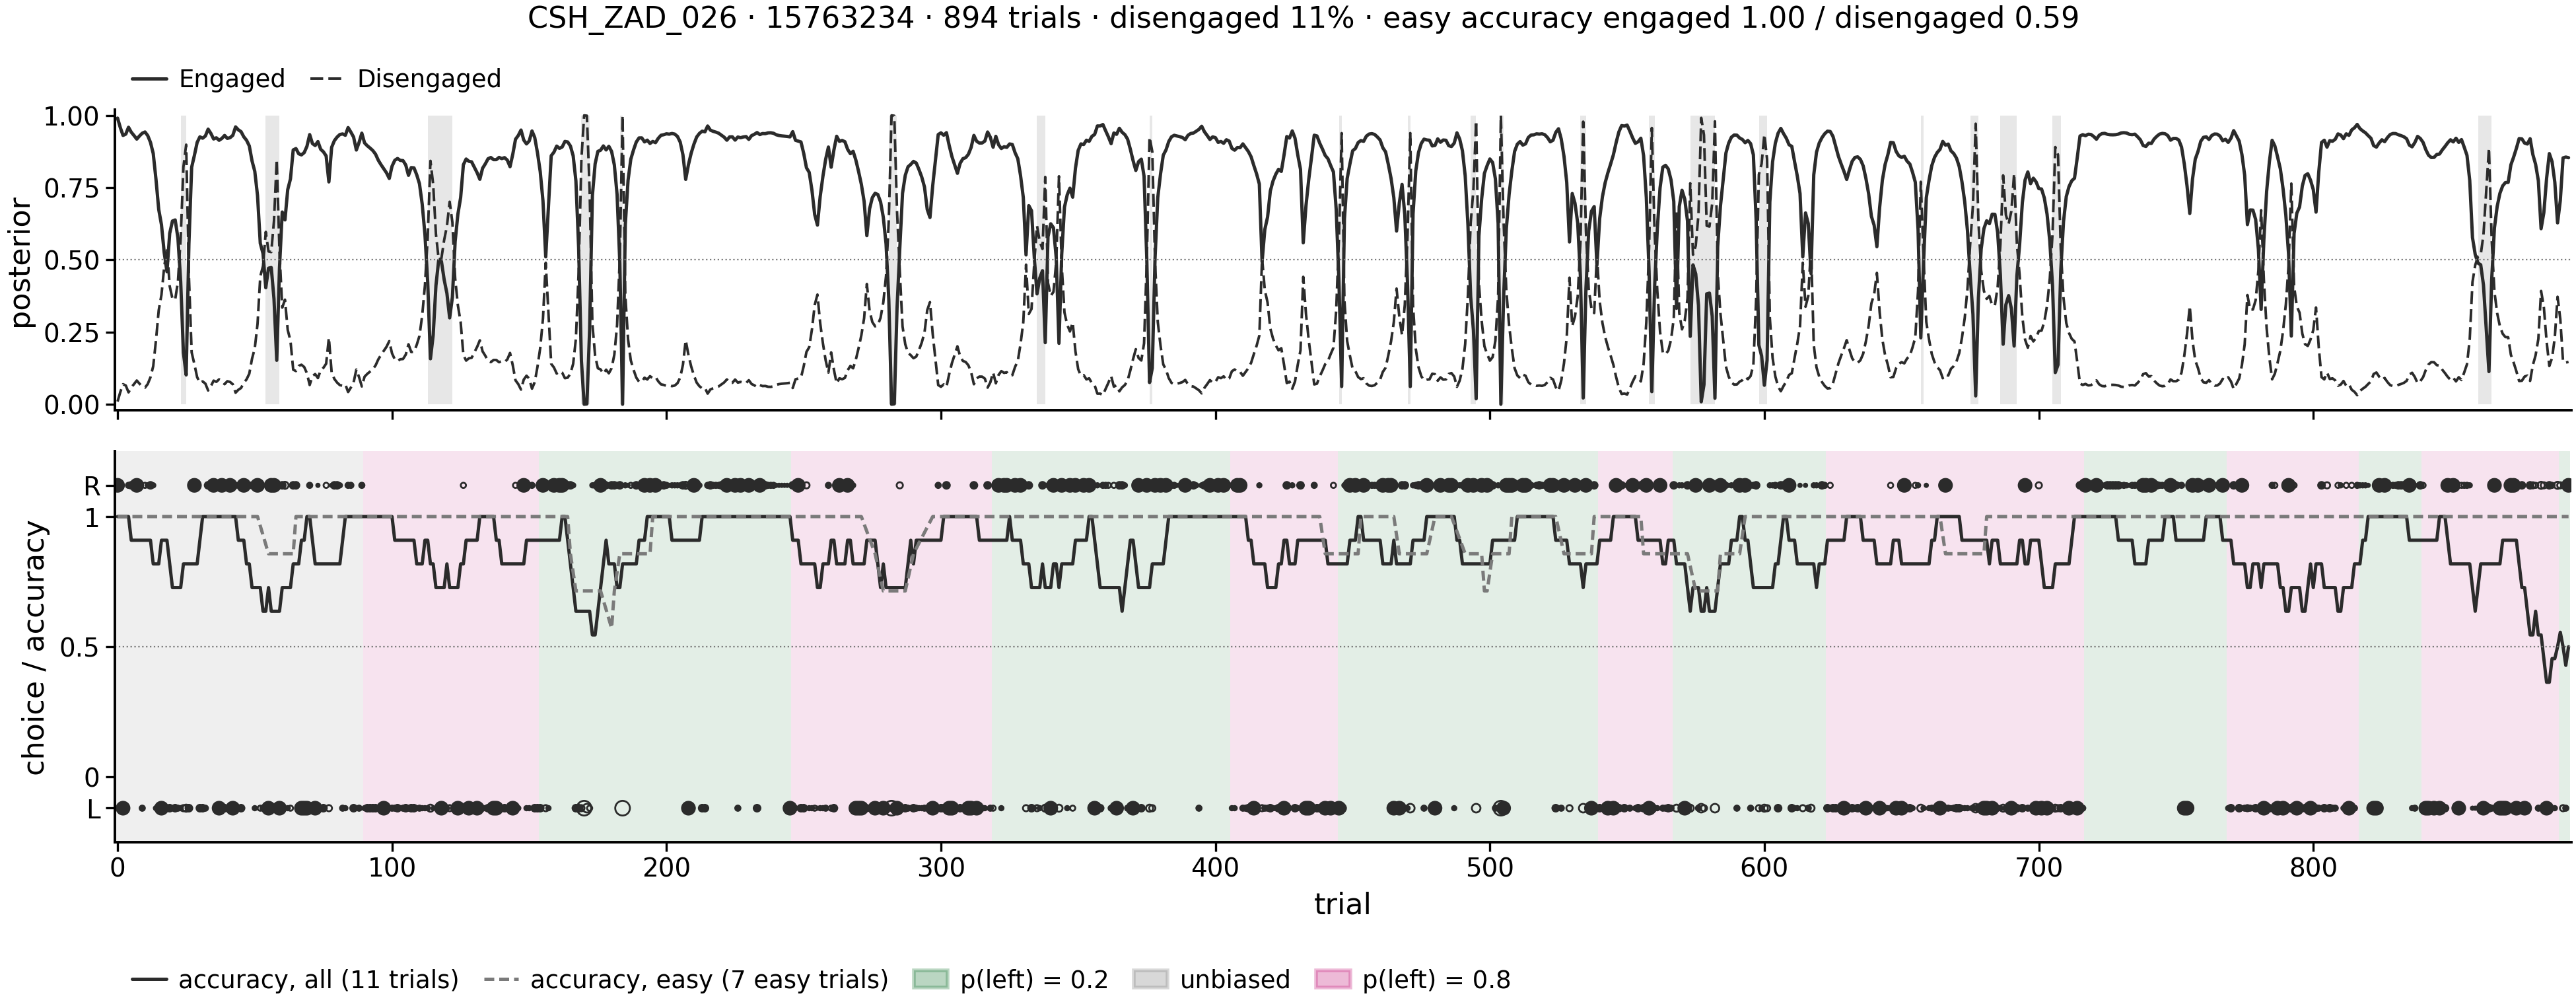

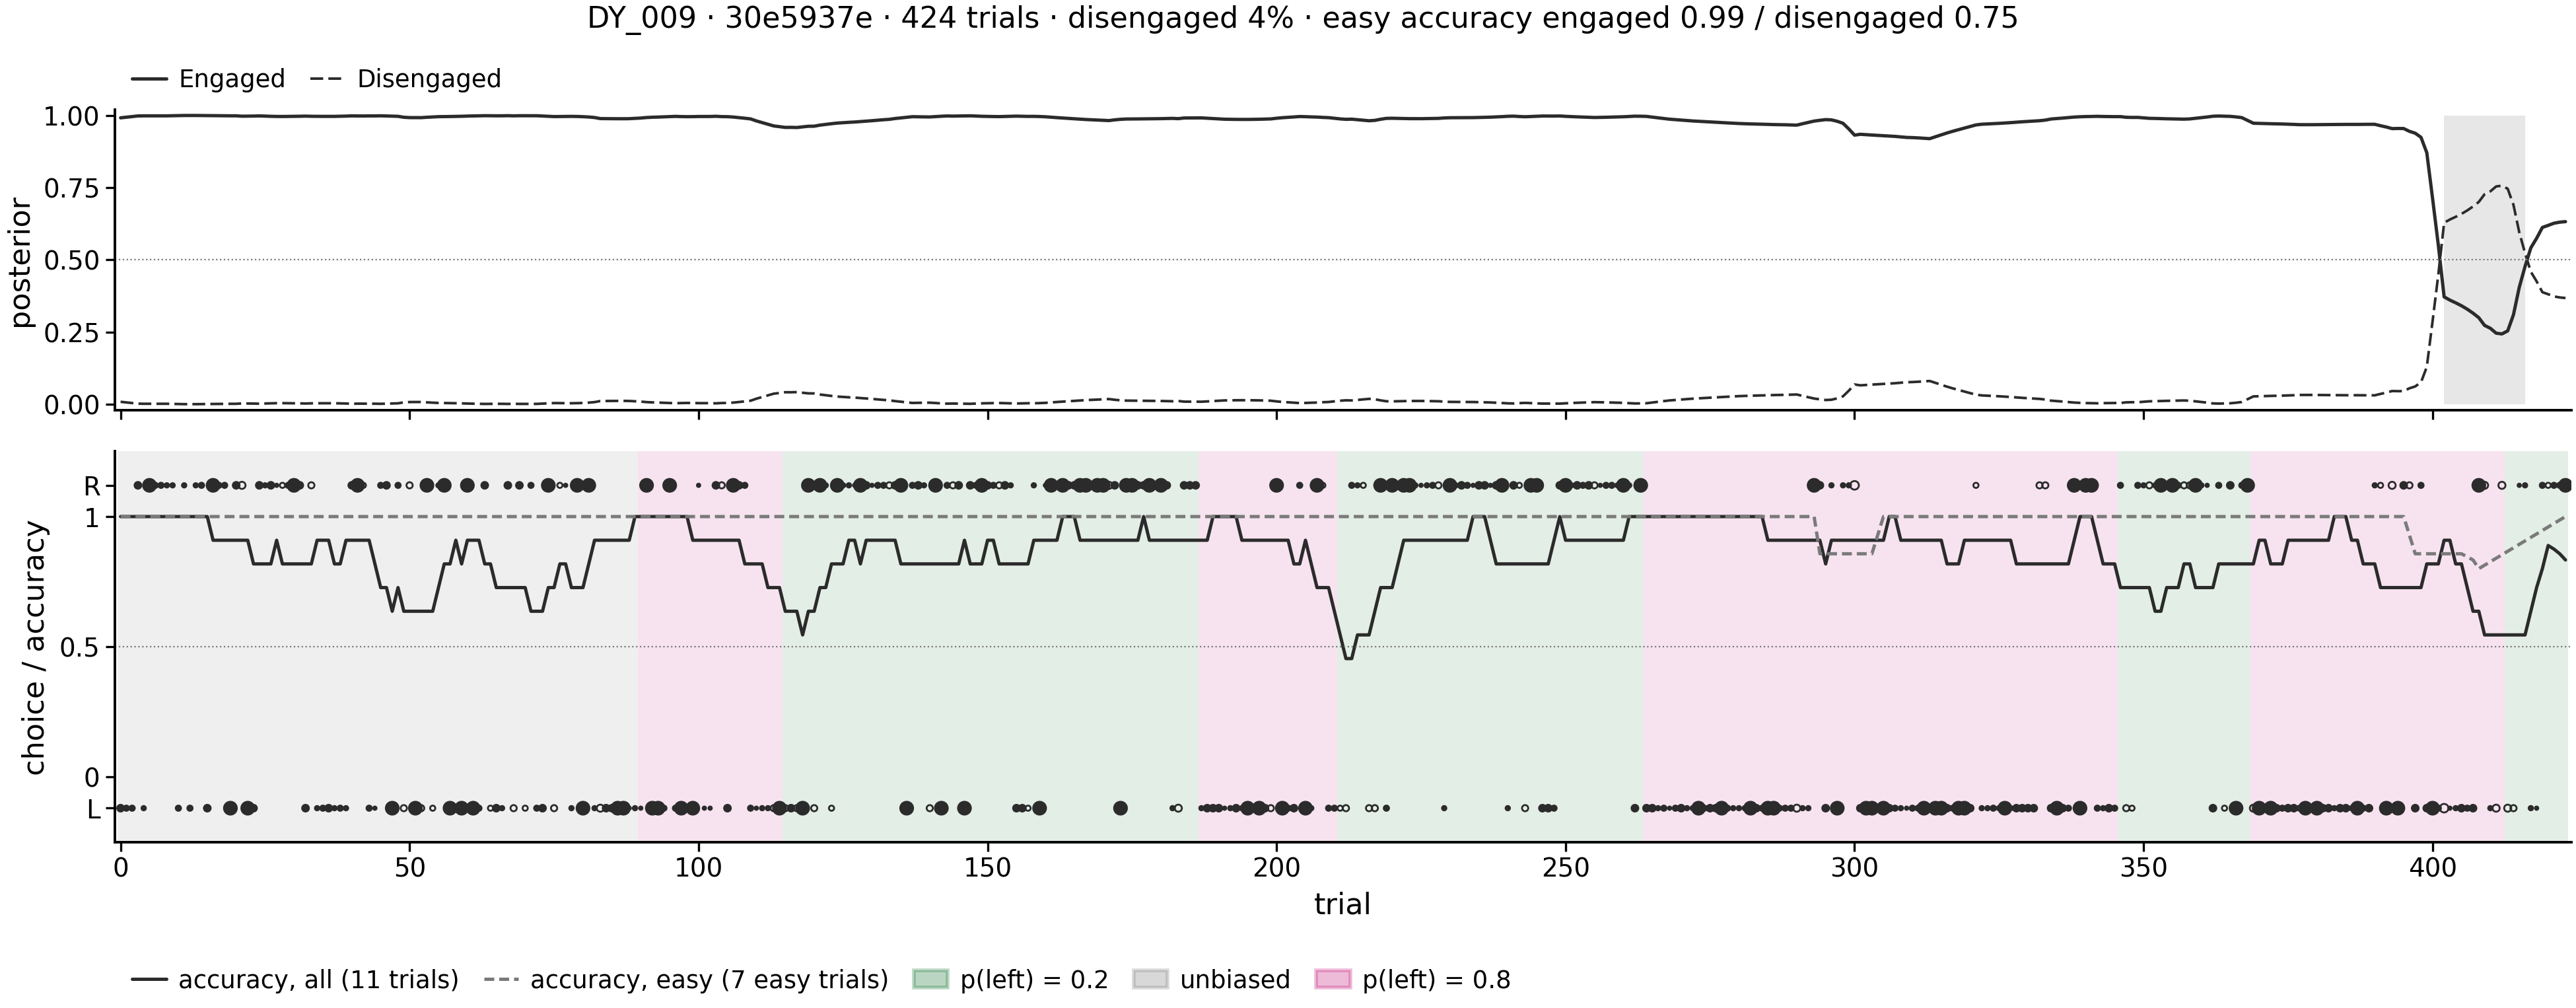

20 figures in /home/ines/repositories/representation_learning_variability/paper-individuality/results/glmhmm_sessions


In [3]:
sessions = sp.pick_sessions(d, N_SESSIONS, animals=ANIMALS, per_animal=PER_ANIMAL, seed=SEED)
paths = sp.save_sessions(d, sessions, OUT_DIR, show=SHOW)
print(f'{len(paths)} figures in {OUT_DIR}')